# EDA: Default of Credit Card Clients

Разведочный анализ сырых данных: структура, качество, целевая переменная, связь признаков с дефолтом. Выводы определяют правила валидации (`src/data/validation.py`), очистку (`src/data/make_dataset.py`) и Feature Engineering (`src/features/build_features.py`).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.config import BILL_COLS, PAY_AMT_COLS, PAY_STATUS_COLS, TARGET
from src.data.make_dataset import clean_data, load_raw
from src.features.build_features import add_features

sns.set_theme(style="whitegrid")
raw = load_raw(ROOT / "data/raw/UCI_Credit_Card.csv")
print(raw.shape)
raw.head()

(30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


## 1. Качество данных

In [2]:
quality = pd.DataFrame({"dtype": raw.dtypes.astype(str), "nulls": raw.isna().sum(), "n_unique": raw.nunique(),
                        "min": raw.min(), "max": raw.max()})
print(f"Полных дубликатов (без ID): {raw.drop(columns='ID').duplicated().sum()}")
quality

Полных дубликатов (без ID): 35


,dtype,nulls,n_unique,min,max
ID,int64,0,30000,1,30000
LIMIT_BAL,int64,0,81,10000,1000000
SEX,int64,0,2,1,2
EDUCATION,int64,0,7,0,6
MARRIAGE,int64,0,4,0,3
AGE,int64,0,56,21,79
PAY_0,int64,0,11,-2,8
PAY_2,int64,0,11,-2,8
PAY_3,int64,0,11,-2,8
PAY_4,int64,0,11,-2,8


In [3]:
for col in ["SEX", "EDUCATION", "MARRIAGE"]:
    print(col, raw[col].value_counts().sort_index().to_dict())

SEX {1: 11888, 2: 18112}
EDUCATION {0: 14, 1: 10585, 2: 14030, 3: 4917, 4: 123, 5: 280, 6: 51}
MARRIAGE {0: 54, 1: 13659, 2: 15964, 3: 323}


* Пропусков нет, все колонки числовые.
* В `EDUCATION` встречаются недокументированные коды **0, 5, 6**, в `MARRIAGE` — код **0**. По описанию датасета допустимы 1–4 и 1–3, поэтому при очистке они объединяются с категорией «другое».
* `PAY_*` принимают значения от −2 до 8: −2 — нет потребления, −1 — оплачено вовремя, 0 — револьверный кредит, 1..8 — месяцы просрочки.
* `BILL_AMT*` бывают отрицательными (переплата), это не ошибка. Эти диапазоны зашиты в набор правил Great Expectations.

## 2. Целевая переменная

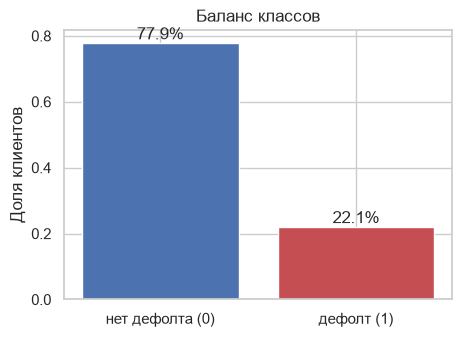

In [4]:
fig, ax = plt.subplots(figsize=(5, 3.5))
share = raw[TARGET].value_counts(normalize=True).sort_index()
ax.bar(["нет дефолта (0)", "дефолт (1)"], share.values, color=["#4C72B0", "#C44E52"])
for i, v in enumerate(share.values):
    ax.text(i, v, f"{v:.1%}", ha="center", va="bottom")
ax.set(title="Баланс классов", ylabel="Доля клиентов")
plt.show()

Дефолтов около 22%: классы несбалансированы. Поэтому основная метрика — **ROC-AUC**, стратифицированное разбиение и CV, а порог классификации подбирается под F1, а не берётся равным 0.5.

## 3. Признаки и риск дефолта

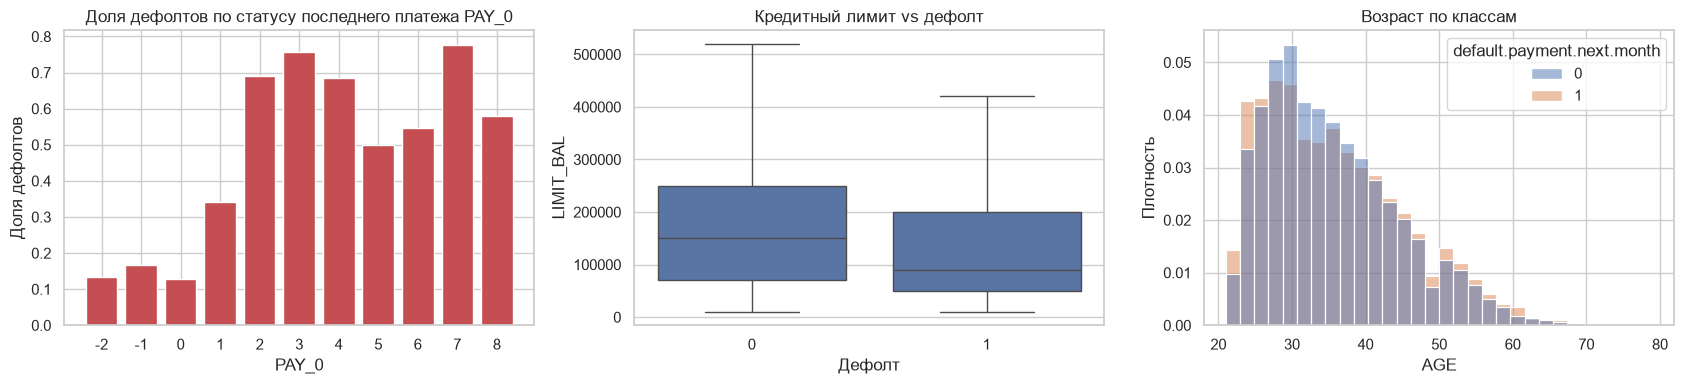

PAY_0,-2,-1,0,1,2,3,4,5,6,7,8
mean,0.132,0.168,0.128,0.34,0.691,0.758,0.684,0.5,0.545,0.778,0.579
size,2750.000,5682.000,14737.000,3667.00,2666.000,322.000,76.000,26.0,11.000,9.000,19.000


In [5]:
df = clean_data(raw)
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
rate = df.groupby("PAY_0")[TARGET].agg(["mean", "size"])
axes[0].bar(rate.index.astype(str), rate["mean"], color="#C44E52")
axes[0].set(title="Доля дефолтов по статусу последнего платежа PAY_0", xlabel="PAY_0", ylabel="Доля дефолтов")
sns.boxplot(data=df, x=TARGET, y="LIMIT_BAL", ax=axes[1], showfliers=False)
axes[1].set(title="Кредитный лимит vs дефолт", xlabel="Дефолт", ylabel="LIMIT_BAL")
sns.histplot(data=df, x="AGE", hue=TARGET, stat="density", common_norm=False, bins=30, ax=axes[2])
axes[2].set(title="Возраст по классам", xlabel="AGE", ylabel="Плотность")
plt.tight_layout(); plt.show()
rate.round(3).T

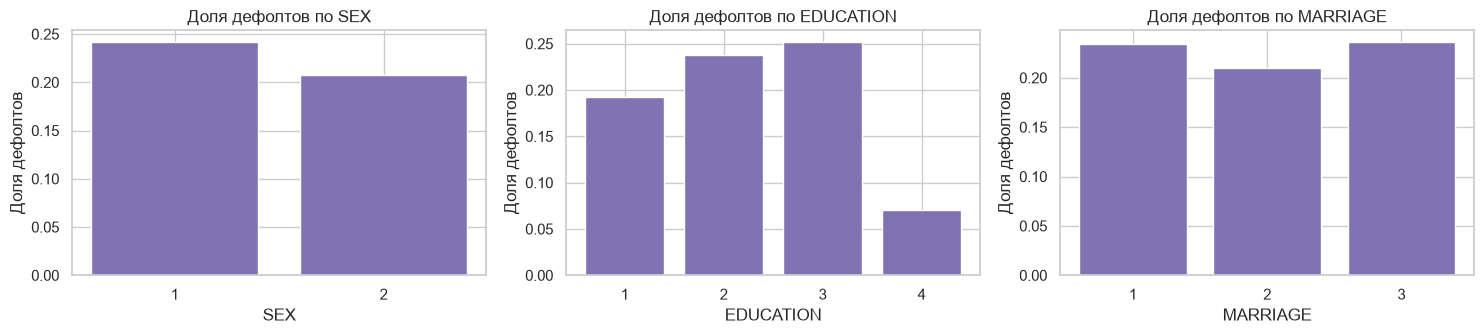

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, col in zip(axes, ["SEX", "EDUCATION", "MARRIAGE"]):
    r = df.groupby(col)[TARGET].mean()
    ax.bar(r.index.astype(str), r.values, color="#8172B3")
    ax.set(title=f"Доля дефолтов по {col}", xlabel=col, ylabel="Доля дефолтов")
plt.tight_layout(); plt.show()

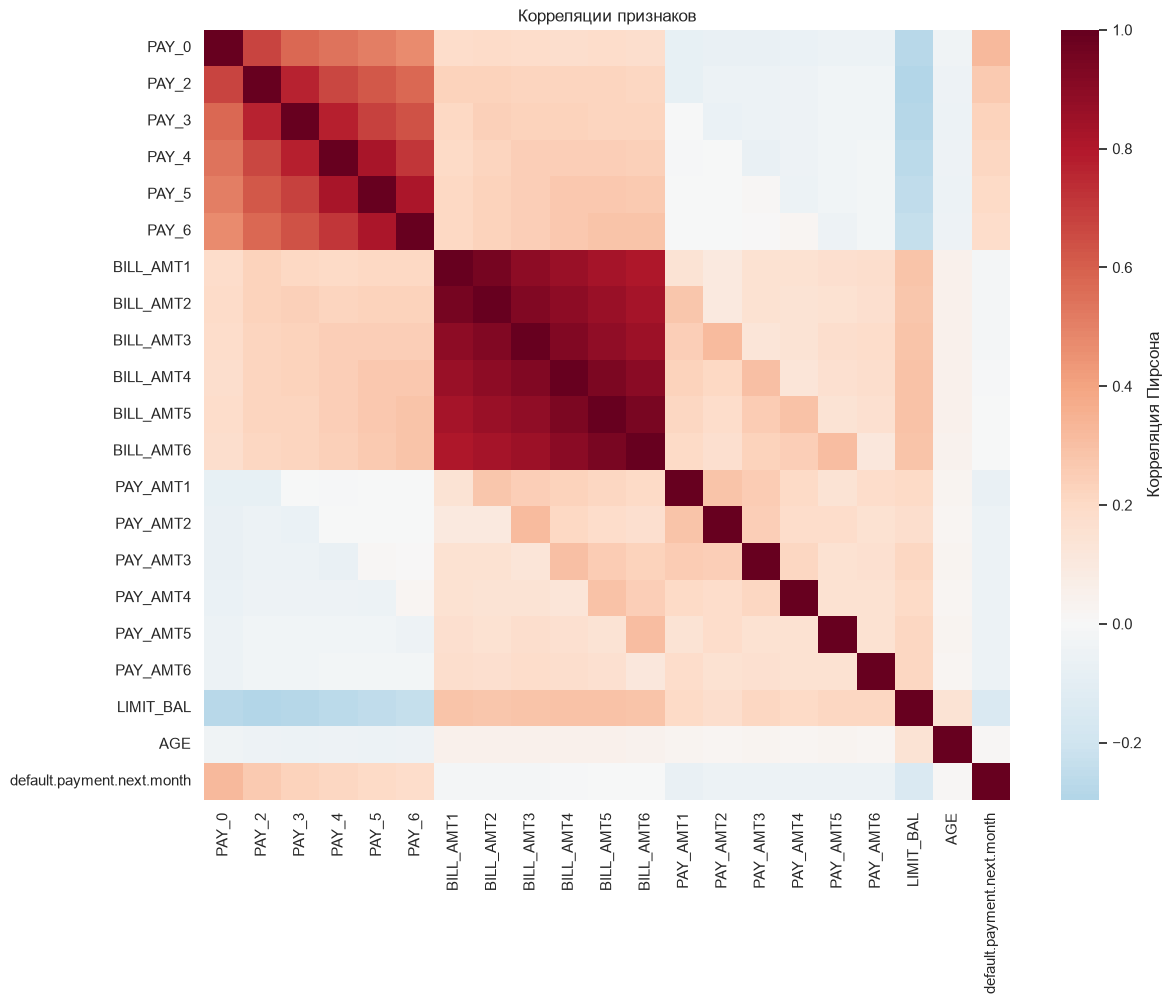

PAY_0        0.325
PAY_2        0.264
PAY_3        0.235
PAY_4        0.217
PAY_5        0.204
PAY_6        0.187
LIMIT_BAL   -0.154
PAY_AMT1    -0.073
PAY_AMT2    -0.059
PAY_AMT4    -0.057
Name: default.payment.next.month, dtype: float64

In [7]:
corr = df[PAY_STATUS_COLS + BILL_COLS + PAY_AMT_COLS + ["LIMIT_BAL", "AGE", TARGET]].corr()
fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(corr, cmap="RdBu_r", center=0, ax=ax, cbar_kws={"label": "Корреляция Пирсона"})
ax.set_title("Корреляции признаков")
plt.show()
corr[TARGET].drop(TARGET).sort_values(key=np.abs, ascending=False).head(10).round(3)

* Сильнейший предиктор — **история просрочек** `PAY_*`: при `PAY_0 ≥ 2` доля дефолтов резко растёт. Отсюда агрегаты истории: максимальная и средняя просрочка, число месяцев с просрочкой.
* `BILL_AMT1..6` сильно коррелируют между собой (мультиколлинеарность). Вместо шести сырых значений информативнее **средний счёт, загрузка лимита (utilization) и тренд**.
* Чем выше лимит, тем ниже риск: банк выдаёт большие лимиты надёжным клиентам. Отношение лимита к возрасту и доля оплаченных счетов (`payment_ratio`) дополняют картину.
* Зависимость от возраста нелинейная (U-образная), поэтому возраст **биннингуется** в категории.

## 4. Проверка сконструированных признаков

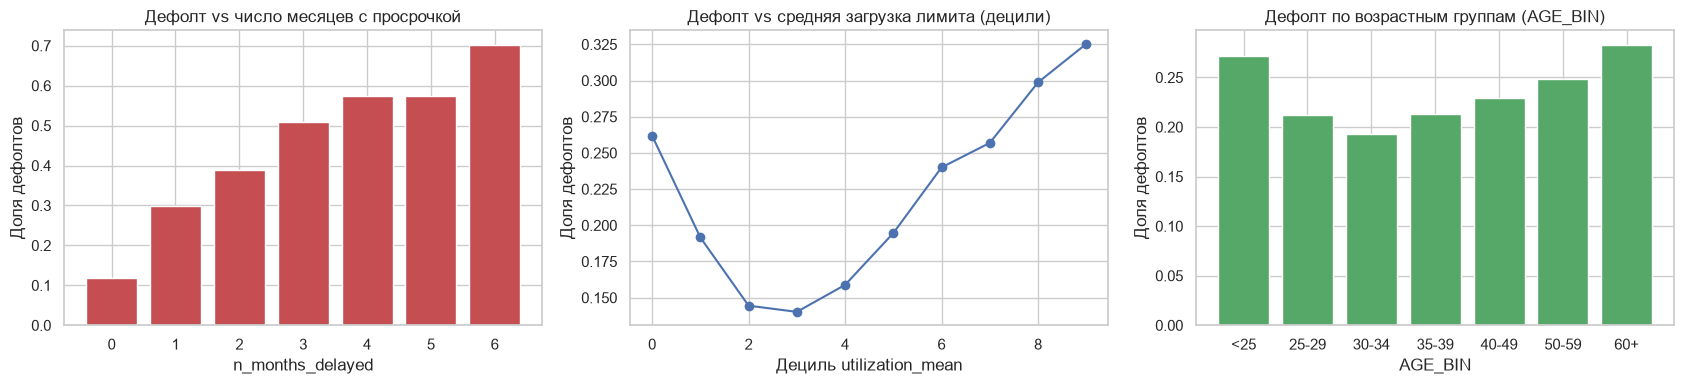

In [8]:
fe = add_features(df)
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
r = fe.groupby("n_months_delayed")[TARGET].mean()
axes[0].bar(r.index.astype(str), r.values, color="#C44E52")
axes[0].set(title="Дефолт vs число месяцев с просрочкой", xlabel="n_months_delayed", ylabel="Доля дефолтов")
fe["util_bin"] = pd.qcut(fe["utilization_mean"].clip(-0.5, 2), 10, duplicates="drop")
r = fe.groupby("util_bin", observed=True)[TARGET].mean()
axes[1].plot(range(len(r)), r.values, "o-")
axes[1].set(title="Дефолт vs средняя загрузка лимита (децили)", xlabel="Дециль utilization_mean", ylabel="Доля дефолтов")
r = fe.groupby("AGE_BIN")[TARGET].mean().reindex(["<25", "25-29", "30-34", "35-39", "40-49", "50-59", "60+"])
axes[2].bar(r.index, r.values, color="#55A868")
axes[2].set(title="Дефолт по возрастным группам (AGE_BIN)", xlabel="AGE_BIN", ylabel="Доля дефолтов")
plt.tight_layout(); plt.show()

Сконструированные признаки монотонно связаны с риском: число месяцев просрочки и загрузка лимита, а возрастные группы подтверждают нелинейность по возрасту. Вклад Feature Engineering в качество измеряется в MLflow сравнением экспериментов `logreg_raw` и `logreg_fe`.